In [1]:
# Basics
import numpy as np
import os

# Machine Learning
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm.notebook import tqdm

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print(f'GPU available: {torch.cuda.is_available()}')

GPU available: True


In [3]:
path = '/kaggle/input'
print("Path to dataset files:", path)

for dirname, _, filenames in os.walk(path):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        break

Path to dataset files: /kaggle/input


# Dataset

In [4]:
class XrayDataset(Dataset):
  def __init__(self, data_dir, transform=None, target_transform=None):
      self.data = ImageFolder(data_dir, transform=transform)

  def __len__(self):
    return len(self.data)

  def __getitem__(self, idx):
      return self.data[idx]

  @property
  def classes(self):
      return self.data.classes

In [5]:
train_dir = os.path.join('data', 'chest_xray', 'train')
val_dir = os.path.join('data', 'chest_xray', 'val')
test_dir = os.path.join('data', 'chest_xray', 'test')

transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

train_dataset = XrayDataset(train_dir, transform)
val_dataset = XrayDataset(val_dir, transform)
test_dataset = XrayDataset(test_dir, transform)

In [6]:
for image, label in train_dataset:
    break

print(image.shape)

torch.Size([1, 150, 150])


# Dataloader

In [7]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0, pin_memory=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=True)

# Model

In [8]:
class PneumoniaModel(nn.Module):
    def __init__(self):
        super(PneumoniaModel, self).__init__()

        # Block 1
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

        # Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.dropout2 = nn.Dropout(0.1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

        # Block 3
        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

        # Block 4
        self.conv4 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.dropout4 = nn.Dropout(0.2)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

        # Block 5
        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)
        self.dropout5 = nn.Dropout(0.2)
        self.bn5 = nn.BatchNorm2d(256)
        self.pool5 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

        # Fully connected layers
        self.fc1 = nn.Linear(256 * 4 * 4, 128)
        self.dropout_fc = nn.Dropout(0.2)
        self.fc2 = nn.Linear(128, 1)

        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # Block 1
        x = self.relu(self.conv1(x))
        x = self.bn1(x)
        x = self.pool1(x)

        # Block 2
        x = self.relu(self.conv2(x))
        x = self.dropout2(x)
        x = self.bn2(x)
        x = self.pool2(x)

        # Block 3
        x = self.relu(self.conv3(x))
        x = self.bn3(x)
        x = self.pool3(x)

        # Block 4
        x = self.relu(self.conv4(x))
        x = self.dropout4(x)
        x = self.bn4(x)
        x = self.pool4(x)

        # Block 5
        x = self.relu(self.conv5(x))
        x = self.dropout5(x)
        x = self.bn5(x)
        x = self.pool5(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully connected
        x = self.relu(self.fc1(x))
        x = self.dropout_fc(x)
        x = self.sigmoid(self.fc2(x))

        return x

# Create model
model = PneumoniaModel()

# Optimizer and loss (equivalent to compile)
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001)
criterion = nn.BCELoss()  # Binary Cross Entropy

# For a more detailed summary:
from torchsummary import summary
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

summary(model, (1, 150, 150))
print(device)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 150, 150]             320
              ReLU-2         [-1, 32, 150, 150]               0
       BatchNorm2d-3         [-1, 32, 150, 150]              64
         MaxPool2d-4           [-1, 32, 75, 75]               0
            Conv2d-5           [-1, 64, 75, 75]          18,496
              ReLU-6           [-1, 64, 75, 75]               0
           Dropout-7           [-1, 64, 75, 75]               0
       BatchNorm2d-8           [-1, 64, 75, 75]             128
         MaxPool2d-9           [-1, 64, 37, 37]               0
           Conv2d-10           [-1, 64, 37, 37]          36,928
             ReLU-11           [-1, 64, 37, 37]               0
      BatchNorm2d-12           [-1, 64, 37, 37]             128
        MaxPool2d-13           [-1, 64, 18, 18]               0
           Conv2d-14          [-1, 128,

In [9]:
# Optimizer and loss
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.001)
criterion = nn.BCELoss()

# Learning rate scheduler (equivalent to ReduceLROnPlateau)
scheduler = ReduceLROnPlateau(
    optimizer,
    mode='max',           # 'max' because we're monitoring accuracy
    factor=0.3,           # multiply lr by 0.3
    patience=2,           # wait 2 epochs before reducing
    min_lr=0.000001       # minimum learning rate
)

In [12]:
# Training function
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc= 'Training loop'):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs.squeeze(), labels.float())
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predicted = (outputs.squeeze() > 0).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc='Validation loop'):
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs.squeeze(), labels.float())

            running_loss += loss.item() * images.size(0)
            predicted = (outputs.squeeze() > 0.5).float()
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [13]:
# Training loop for 12 epochs
epochs = 12
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

for epoch in range(epochs):
    print(f'Epoch {epoch+1}/{epochs}')
    print('-' * 30)

    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)

    # Validate
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    # Store history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # Print metrics
    print(f'Train Loss: {train_loss:.4f} - Train Acc: {train_acc:.4f}')
    print(f'Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.4f}')

    # Update learning rate based on val_accuracy
    scheduler.step(val_acc)

    print(f'Current LR: {optimizer.param_groups[0]["lr"]:.6f}')
    print()

print('Training complete!')

Epoch 1/12
------------------------------


Training loop:   0%|          | 0/82 [00:00<?, ?it/s]

Validation loop:   0%|          | 0/1 [00:00<?, ?it/s]

Train Loss: 25.7094 - Train Acc: 0.7429
Val Loss: 44.6598 - Val Acc: 0.5000
Current LR: 0.000027

Epoch 2/12
------------------------------


Training loop:   0%|          | 0/82 [00:00<?, ?it/s]

Validation loop:   0%|          | 0/1 [00:00<?, ?it/s]

... (27 outputs left out)

Train Loss: 25.7094 - Train Acc: 0.7429
Val Loss: 44.6458 - Val Acc: 0.5000
Current LR: 0.000001

Epoch 12/12
------------------------------


Training loop:   0%|          | 0/82 [00:00<?, ?it/s]

Validation loop:   0%|          | 0/1 [00:00<?, ?it/s]

Train Loss: 25.7094 - Train Acc: 0.7429
Val Loss: 44.6598 - Val Acc: 0.5000
Current LR: 0.000001

Training complete!


In [13]:
# Save model
torch.save(model, 'pneumonia_model_full.pth')

In [14]:
# Save weights
torch.save(model.state_dict(), 'pneumonia_model.pth')

In [181]:
# Load the model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = PneumoniaModel().to(device)
model.load_state_dict(torch.load('pneumonia_model.pth'))
model.eval()  # Set to evaluation mode

# Create test loader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

# Test function
def test_model(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device).float()

            outputs = model(images)            # shape: [batch,1] or [batch]
            outputs = outputs.view(-1)        # flatten to [batch]
            predicted = (outputs > 0).float() # threshold at 0 for BCEWithLogitsLoss

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            # Store for confusion matrix
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = correct / total
    print(f'Test Accuracy: {accuracy:.4f} ({correct}/{total})')

    return all_preds, all_labels


# Run test
predictions, labels = test_model(model, test_loader, device)

Test Accuracy: 0.6250 (390/624)


In [142]:
# FGSM attack code
def fgsm_attack(image, epsilon, data_grad):
    # print(f'Original shape: {image.shape}')
    # Collect the element-wise sign of the data gradient
    sign_data_grad = data_grad.sign()
    # Create the perturbed image by adjusting each pixel of the input image
    perturbed_image = image + epsilon*sign_data_grad
    # Adding clipping to maintain [0,1] range
    # perturbed_image = torch.clamp(perturbed_image, 0, 1)
    # print(f'Perturbed shape: {perturbed_image.shape}')
    # Return the perturbed image
    return perturbed_image

# restores the tensors to their original scale
def denorm(batch, mean=[0.1307], std=[0.3081]):
    """
    Convert a batch of tensors to their original scale.

    Args:
        batch (torch.Tensor): Batch of normalized tensors.
        mean (torch.Tensor or list): Mean used for normalization.
        std (torch.Tensor or list): Standard deviation used for normalization.

    Returns:
        torch.Tensor: batch of tensors without normalization applied to them.
    """
    if isinstance(mean, list):
        mean = torch.tensor(mean).to(device)
    if isinstance(std, list):
        std = torch.tensor(std).to(device)

    return batch * std.view(1, -1, 1, 1) + mean.view(1, -1, 1, 1)

In [177]:
criterion = torch.nn.BCEWithLogitsLoss()

def test_fgsm_binary(model, device, test_loader, epsilon):
    model.eval()

    correct = 0
    attacked = 0
    adv_examples = []


    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        target = target.float()  # ensure float targets

        data.requires_grad = True

        # Forward pass
        output = model(data).squeeze()
        pred = (output > 0).float()

        # Only attack correctly classified samples
        mask = pred.eq(target)
        if mask.sum() == 0:
            continue

        data_correct = data[mask]
        target_correct = target[mask]
        output_correct = output[mask]

        attacked += target_correct.size(0)

        # Compute loss
        loss = criterion(output_correct, target_correct)
        model.zero_grad()
        loss.backward()

        # Gradient for the correctly classified samples
        data_grad = data.grad[mask]

        # FGSM attack
        perturbed_data = data_correct + epsilon * data_grad.sign()
        perturbed_data = torch.clamp(perturbed_data, 0, 1)

        # Re-classify perturbed data
        output_adv = model(perturbed_data).squeeze()
        pred_adv = (output_adv > 0.5).float()

        # Count how many are still correct
        is_correct = pred_adv.eq(target_correct).sum().item()
        correct += is_correct

        # Save only **adversarial examples that fooled the model**
        fooled_mask = ~pred_adv.eq(target_correct)
        for i in range(min(5, fooled_mask.sum().item())):
            idx = fooled_mask.nonzero(as_tuple=True)[0][i]
            adv_examples.append((
                perturbed_data[idx].detach().cpu().numpy(),
                pred[idx].detach().cpu(),      # original prediction
                pred_adv[idx].detach().cpu()   # attacked prediction
            ))

        if len(adv_examples) < 5:
            # Fill remaining slots with near-miss (most vulnerable) samples
            # Vulnerability = smallest |logit| after attack
            with torch.no_grad():
                vulnerability = torch.abs(output_adv)
                sorted_idx = torch.argsort(vulnerability)

                for i in sorted_idx:
                    if len(adv_examples) >= 5:
                        break
                    adv_examples.append((
                        perturbed_data[i].detach().cpu().numpy(),
                        pred[i].detach().cpu(),
                        pred_adv[i].detach().cpu()
                    ))


    acc = correct / attacked if attacked > 0 else 0
    print(
        f"Epsilon: {epsilon:.2f}\t"
        f"Attacked: {attacked}\t"
        f"Correct: {correct}\t"
        f"Accuracy: {acc:.4f}"
    )

    return acc, adv_examples

In [178]:
epsilons = [0, .05, .1, .15, .2, .25, .3]

accuracies = []
examples = []

# Run test for each epsilon
for eps in epsilons:
    acc, ex = test_fgsm_binary(model, device, test_loader, eps)
    accuracies.append(acc)
    examples.append(ex)

Epsilon: 0.00	Attacked: 451	Correct: 451	Accuracy: 1.0000
Epsilon: 0.05	Attacked: 451	Correct: 318	Accuracy: 0.7051
Epsilon: 0.10	Attacked: 451	Correct: 260	Accuracy: 0.5765
Epsilon: 0.15	Attacked: 451	Correct: 277	Accuracy: 0.6142
Epsilon: 0.20	Attacked: 451	Correct: 279	Accuracy: 0.6186
Epsilon: 0.25	Attacked: 451	Correct: 279	Accuracy: 0.6186
Epsilon: 0.30	Attacked: 451	Correct: 279	Accuracy: 0.6186


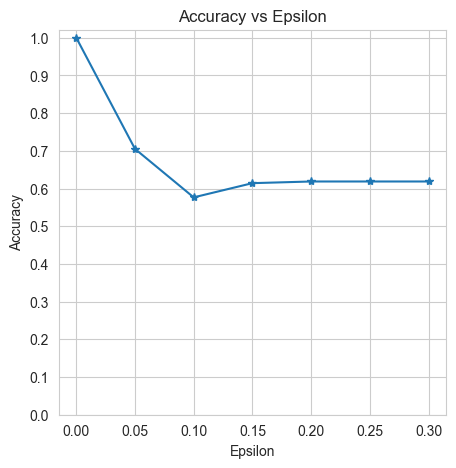

In [179]:
plt.figure(figsize=(5,5))
plt.plot(epsilons, accuracies, "*-")
plt.yticks(np.arange(0, 1.1, step=0.1))
plt.xticks(np.arange(0, .35, step=0.05))
plt.title("Accuracy vs Epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Accuracy")
plt.show()

5


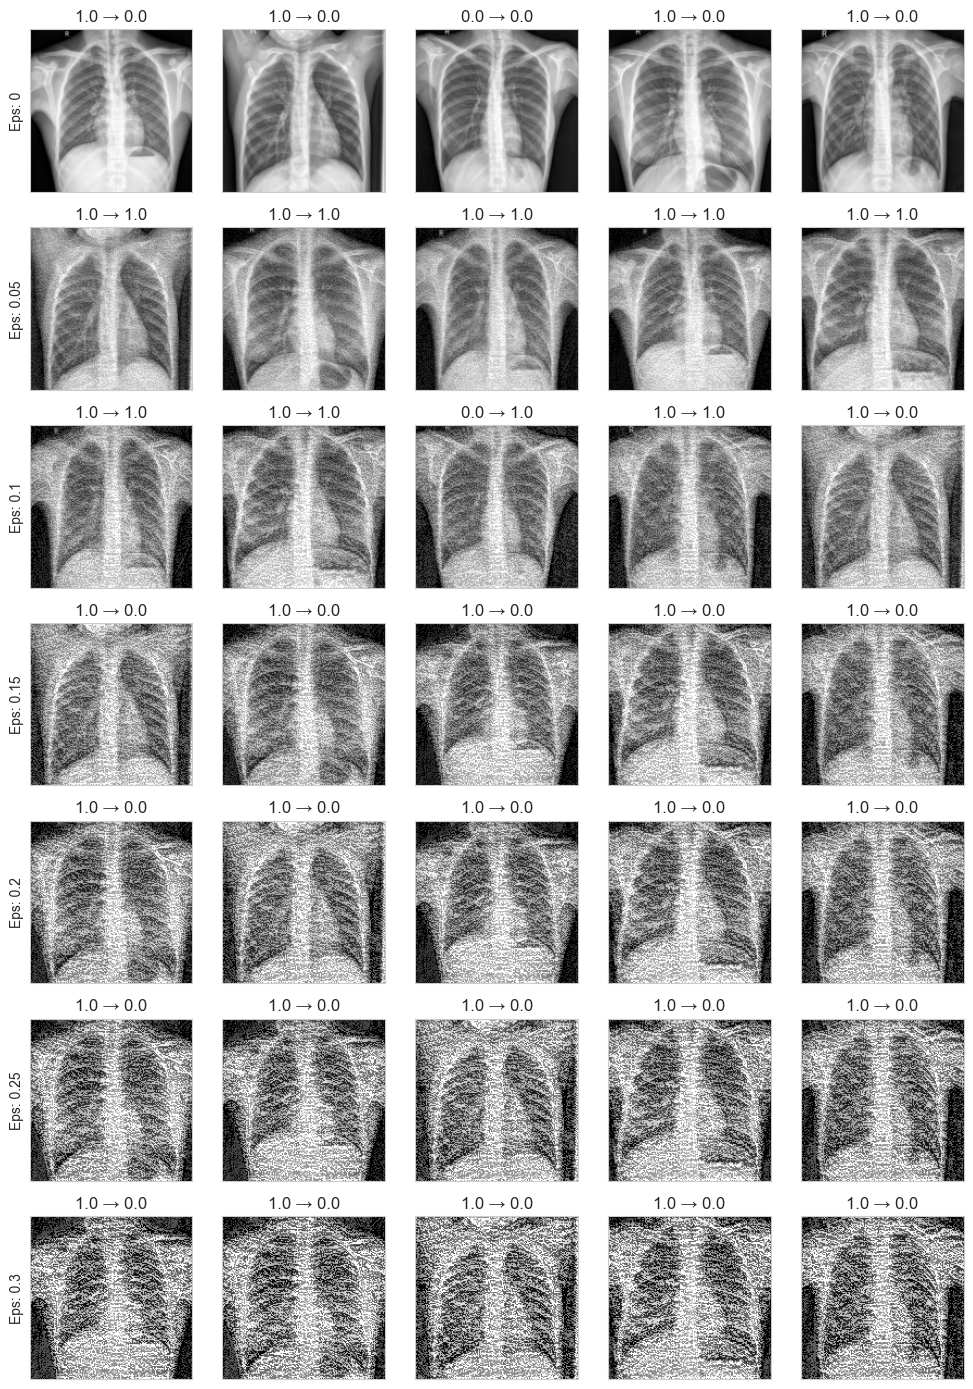

In [180]:
rows = len(epsilons)
cols = min(min(len(ex) for ex in examples), 8)
print(cols)

fig, axes = plt.subplots(rows, cols, figsize=(2*cols, 2*rows))

if rows == 1:
    axes = axes[np.newaxis, :]
if cols == 1:
    axes = axes[:, np.newaxis]

for i in range(rows):
    for j in range(cols):
        ax = axes[i, j]
        ex, orig, adv = examples[i][j]

        k = 0  # choose image from batch

        ax.imshow(ex[k], cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])

        if j == 0:
            ax.set_ylabel(f"Eps: {epsilons[i]}")

        ax.set_title(f"{orig.item()} → {adv.item()}")

plt.tight_layout()
plt.show()
